Image-to-Image Translation with cGAN

Starting Pix2Pix Project

In [ ]:
print("Task 4 - Image-to-Image Translation with cGAN")
print("Pix2Pix project started successfully!")

Task 4 - Image-to-Image Translation with cGAN
Pix2Pix project started successfully!


Checking GPU and TensorFlow

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("✅ GPU is ready!")
else:
    print("⚠️ GPU not detected. Please enable T4 GPU.")

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU is ready!


Downloading Pix2Pix Dataset

In [ ]:
import tensorflow as tf
import os
import tarfile

dataset_url = "http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz"

dataset_path = tf.keras.utils.get_file(
    "facades.tar.gz",
    dataset_url,
    cache_dir=".",
    cache_subdir=""
)

print("Dataset downloaded successfully!")
print("File:", dataset_path)

with tarfile.open(dataset_path, "r:gz") as tar:
    tar.extractall(path=".")

print("Dataset extracted successfully!")
print("Dataset folder exists:", os.path.exists("facades"))

30168306/30168306 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
Dataset downloaded successfully!
File: ./facades.tar.gz


/tmp/ipykernel_3240/1363767380.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=".")


Dataset extracted successfully!
Dataset folder exists: True


Checking Images from Dataset

In [ ]:
import os

train_path = "facades/train"
val_path = "facades/val"
test_path = "facades/test"

print("Training images:", len(os.listdir(train_path)))
print("Validation images:", len(os.listdir(val_path)))
print("Test images:", len(os.listdir(test_path)))

print("\nFirst 5 training files:")
print(os.listdir(train_path)[:5])

Training images: 400
Validation images: 100
Test images: 106

First 5 training files:
['360.jpg', '397.jpg', '314.jpg', '398.jpg', '175.jpg']


Loading and Visualizing a Training Image

Image size: (512, 256)
Image mode: RGB


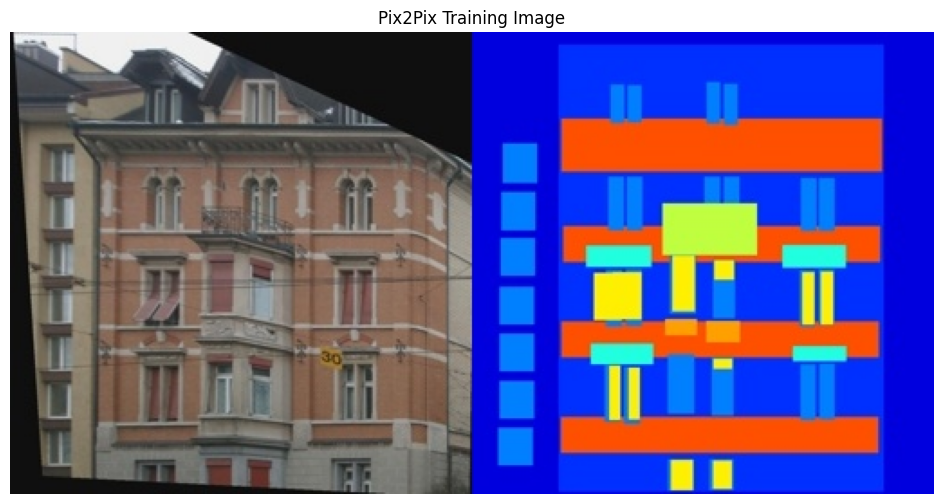

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_file = os.path.join("facades/train", os.listdir("facades/train")[0])

image = Image.open(image_file)

print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(12, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Pix2Pix Training Image")
plt.show()

Seperating Input and Target Image

Input image shape: (256, 256, 3)
Target image shape: (256, 256, 3)


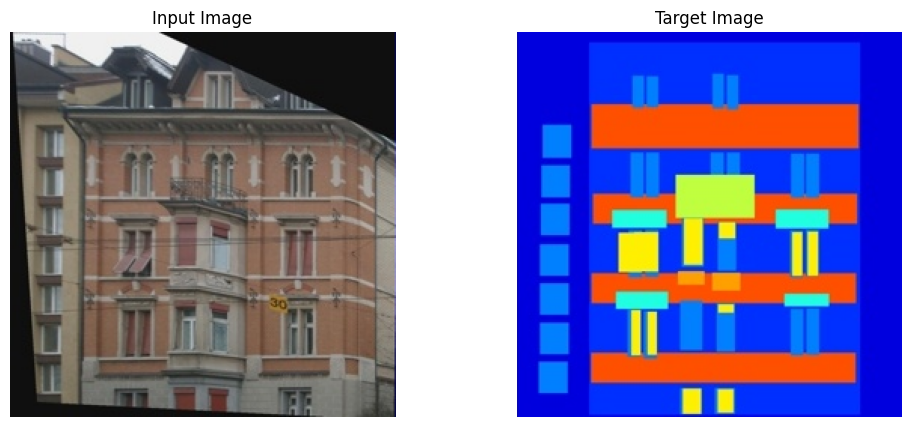

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image = Image.open(image_file)

image_array = np.array(image)

# Split image into two equal halves
width = image_array.shape[1]
half_width = width // 2

input_image = image_array[:, :half_width, :]
target_image = image_array[:, half_width:, :]

print("Input image shape:", input_image.shape)
print("Target image shape:", target_image.shape)

# Display both images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(input_image)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(target_image)
plt.title("Target Image")
plt.axis("off")

plt.show()

Normalizing and Resizing the Images

In [ ]:
IMG_SIZE = 128

def preprocess_image(image):
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)

    # Normalize from [0, 255] to [-1, 1]
    image = (image / 127.5) - 1

    return image

input_processed = preprocess_image(input_image)
target_processed = preprocess_image(target_image)

print("Input processed shape:", input_processed.shape)
print("Target processed shape:", target_processed.shape)
print("Minimum pixel value:", tf.reduce_min(input_processed).numpy())
print("Maximum pixel value:", tf.reduce_max(input_processed).numpy())

Input processed shape: (128, 128, 3)
Target processed shape: (128, 128, 3)
Minimum pixel value: -0.95686275
Maximum pixel value: 0.9372549


Creating Pix2Pix Generator

In [ ]:
from tensorflow.keras import layers

def build_generator():
    inputs = layers.Input(shape=(128, 128, 3))

    # Encoder
    e1 = layers.Conv2D(64, 4, strides=2, padding="same")(inputs)
    e1 = layers.LeakyReLU(0.2)(e1)

    e2 = layers.Conv2D(128, 4, strides=2, padding="same")(e1)
    e2 = layers.BatchNormalization()(e2)
    e2 = layers.LeakyReLU(0.2)(e2)

    e3 = layers.Conv2D(256, 4, strides=2, padding="same")(e2)
    e3 = layers.BatchNormalization()(e3)
    e3 = layers.LeakyReLU(0.2)(e3)

    # Bottleneck
    b = layers.Conv2D(512, 4, strides=2, padding="same")(e3)
    b = layers.ReLU()(b)

    # Decoder
    d1 = layers.Conv2DTranspose(256, 4, strides=2, padding="same")(b)
    d1 = layers.BatchNormalization()(d1)
    d1 = layers.ReLU()(d1)
    d1 = layers.Concatenate()([d1, e3])

    d2 = layers.Conv2DTranspose(128, 4, strides=2, padding="same")(d1)
    d2 = layers.BatchNormalization()(d2)
    d2 = layers.ReLU()(d2)
    d2 = layers.Concatenate()([d2, e2])

    d3 = layers.Conv2DTranspose(64, 4, strides=2, padding="same")(d2)
    d3 = layers.BatchNormalization()(d3)
    d3 = layers.ReLU()(d3)
    d3 = layers.Concatenate()([d3, e1])

    outputs = layers.Conv2DTranspose(
        3, 4, strides=2, padding="same", activation="tanh"
    )(d3)

    return tf.keras.Model(inputs, outputs, name="pix2pix_generator")


generator = build_generator()

print("Generator created successfully!")
print("Total parameters:", generator.count_params())

Generator created successfully!
Total parameters: 6174339


Creating Pix2Pix Discriminator

In [ ]:
def build_discriminator():
    input_image = layers.Input(shape=(128, 128, 3))
    target_image = layers.Input(shape=(128, 128, 3))

    # Combine input and target images
    x = layers.Concatenate()([input_image, target_image])

    x = layers.Conv2D(64, 4, strides=2, padding="same")(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(128, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(256, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(512, 4, strides=1, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    output = layers.Conv2D(1, 4, strides=1, padding="same")(x)

    return tf.keras.Model(
        [input_image, target_image],
        output,
        name="pix2pix_discriminator"
    )


discriminator = build_discriminator()

print("Discriminator created successfully!")
print("Total parameters:", discriminator.count_params())

Discriminator created successfully!
Total parameters: 2771393


Creating Loss Function

In [ ]:
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)

LAMBDA = 100

def generator_loss(disc_generated_output, generated_image, target_image):
    # GAN loss
    gan_loss = loss_object(
        tf.ones_like(disc_generated_output),
        disc_generated_output
    )

    # L1 reconstruction loss
    l1_loss = tf.reduce_mean(tf.abs(target_image - generated_image))

    # Total generator loss
    total_loss = gan_loss + (LAMBDA * l1_loss)

    return total_loss, gan_loss, l1_loss


def discriminator_loss(disc_real_output, disc_generated_output):
    real_loss = loss_object(
        tf.ones_like(disc_real_output),
        disc_real_output
    )

    generated_loss = loss_object(
        tf.zeros_like(disc_generated_output),
        disc_generated_output
    )

    total_loss = real_loss + generated_loss

    return total_loss


print("Loss functions created successfully!")
print("L1 Loss weight (Lambda):", LAMBDA)

Loss functions created successfully!
L1 Loss weight (Lambda): 100


Creating Adam Optimizer

In [ ]:
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=2e-4,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=2e-4,
    beta_1=0.5
)

print("Optimizers created successfully!")
print("Learning rate: 0.0002")
print("Beta 1: 0.5")

Optimizers created successfully!
Learning rate: 0.0002
Beta 1: 0.5


Creating Training Dataset Pipeline

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image_pair(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    # Resize combined image
    image = tf.image.resize(image, [128, 256])

    # Split into input and target
    input_image = image[:, :128, :]
    target_image = image[:, 128:, :]

    # Normalize to [-1, 1]
    input_image = (input_image / 127.5) - 1
    target_image = (target_image / 127.5) - 1

    return input_image, target_image


train_files = tf.data.Dataset.list_files(
    "facades/train/*.jpg",
    shuffle=True
)

train_dataset = train_files.map(
    load_image_pair,
    num_parallel_calls=AUTOTUNE
)

train_dataset = train_dataset.batch(1).prefetch(AUTOTUNE)

print("Training dataset pipeline created successfully!")
print("Batch size: 1")

Training dataset pipeline created successfully!
Batch size: 1


Creating Training Step

In [ ]:
@tf.function
def train_step(input_image, target_image):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        # Generate fake image
        generated_image = generator(input_image, training=True)

        # Discriminator predictions
        disc_real_output = discriminator(
            [input_image, target_image],
            training=True
        )

        disc_generated_output = discriminator(
            [input_image, generated_image],
            training=True
        )

        # Calculate losses
        gen_total_loss, gen_gan_loss, gen_l1_loss = generator_loss(
            disc_generated_output,
            generated_image,
            target_image
        )

        disc_total_loss = discriminator_loss(
            disc_real_output,
            disc_generated_output
        )

    # Calculate gradients
    generator_gradients = gen_tape.gradient(
        gen_total_loss,
        generator.trainable_variables
    )

    discriminator_gradients = disc_tape.gradient(
        disc_total_loss,
        discriminator.trainable_variables
    )

    # Update models
    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    return gen_total_loss, disc_total_loss


print("Training step created successfully!")

Training step created successfully!


Starting Training

In [ ]:
EPOCHS = 5

print("Starting Pix2Pix training...")
print("Total epochs:", EPOCHS)

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    total_gen_loss = 0.0
    total_disc_loss = 0.0
    batches = 0

    for input_image, target_image in train_dataset:
        gen_loss, disc_loss = train_step(input_image, target_image)

        total_gen_loss += gen_loss.numpy()
        total_disc_loss += disc_loss.numpy()
        batches += 1

    avg_gen_loss = total_gen_loss / batches
    avg_disc_loss = total_disc_loss / batches

    print(f"Generator Loss: {avg_gen_loss:.4f}")
    print(f"Discriminator Loss: {avg_disc_loss:.4f}")

print("\nTraining completed successfully!")

Starting Pix2Pix training...
Total epochs: 5

Epoch 1/5
Generator Loss: 45.8679
Discriminator Loss: 0.4957

Epoch 2/5
Generator Loss: 42.0023
Discriminator Loss: 0.4473

Epoch 3/5
Generator Loss: 40.7767
Discriminator Loss: 0.4980

Epoch 4/5
Generator Loss: 39.6298
Discriminator Loss: 0.5516

Epoch 5/5
Generator Loss: 38.4850
Discriminator Loss: 0.4992

Training completed successfully!


Generating Pix2Pix Result

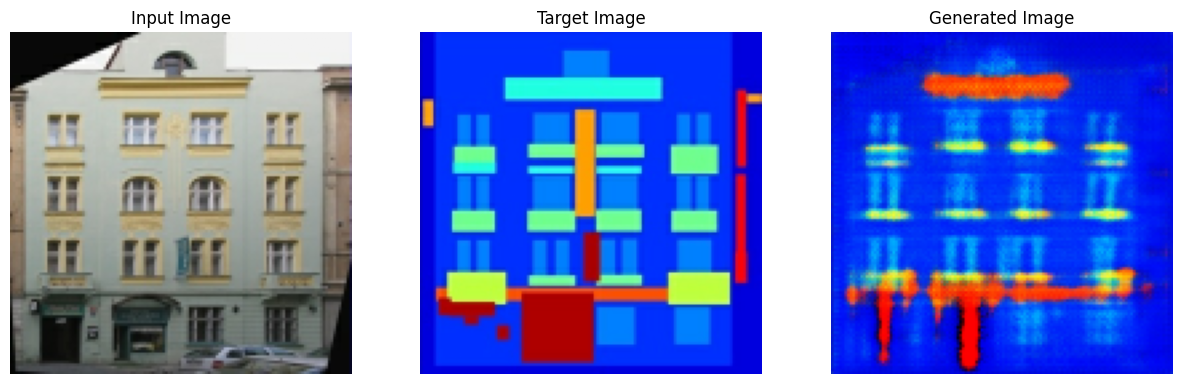

In [ ]:
import matplotlib.pyplot as plt

# Take one image from the training dataset
for input_image, target_image in train_dataset.take(1):
    generated_image = generator(input_image, training=False)

# Convert [-1, 1] back to [0, 1]
def display_image(image):
    image = (image + 1) / 2
    image = tf.clip_by_value(image, 0, 1)
    return image

input_display = display_image(input_image[0])
target_display = display_image(target_image[0])
generated_display = display_image(generated_image[0])

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_display)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(target_display)
plt.title("Target Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(generated_display)
plt.title("Generated Image")
plt.axis("off")

plt.show()

Saving Generated Result

In [ ]:
from PIL import Image
import numpy as np

# Convert generated image from [-1, 1] to [0, 255]
generated_array = ((generated_display.numpy()) * 255).astype(np.uint8)

generated_pil = Image.fromarray(generated_array)
generated_pil.save("pix2pix_generated.png")

print("Generated image saved successfully!")
print("File: pix2pix_generated.png")

Generated image saved successfully!
File: pix2pix_generated.png


Saving Trained Models

In [ ]:
generator.save("pix2pix_generator.keras")
discriminator.save("pix2pix_discriminator.keras")

print("Models saved successfully!")
print("Generator: pix2pix_generator.keras")
print("Discriminator: pix2pix_discriminator.keras")

Models saved successfully!
Generator: pix2pix_generator.keras
Discriminator: pix2pix_discriminator.keras


Creating README.md

In [ ]:
readme = """
# Prodigy Task 4 - Image-to-Image Translation with cGAN

## Objective
The objective of this project is to implement image-to-image translation using a Conditional Generative Adversarial Network (cGAN).

## Model
This project uses the Pix2Pix architecture.

## Dataset
The Facades dataset is used. It contains building facade images and their corresponding label/target images.

## Workflow
1. Download the Facades dataset.
2. Split each image into input and target images.
3. Resize images to 128x128 pixels.
4. Normalize pixel values to the range [-1, 1].
5. Build a Pix2Pix Generator.
6. Build a Pix2Pix Discriminator.
7. Train the Generator and Discriminator using GAN and L1 losses.
8. Generate translated images from input images.
9. Save the generated result and trained models.

## Training
The model was trained for 5 epochs using:
- Batch size: 1
- Learning rate: 0.0002
- Beta 1: 0.5
- L1 loss weight: 100

## Output
The trained Generator produces an image corresponding to the input building facade.

## Files
- pix2pix_generated.png - Generated output image
- pix2pix_generator.keras - Trained Generator
- pix2pix_discriminator.keras - Trained Discriminator
- README.md - Project documentation
- PRODIGY_GA_04_Image_to_Image_Translation_cGAN.ipynb - Complete notebook

## Conclusion
This project demonstrates image-to-image translation using a Conditional GAN and the Pix2Pix architecture.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


Final Project Files Check

In [ ]:
import os

files = [
    "pix2pix_generated.png",
    "pix2pix_generator.keras",
    "pix2pix_discriminator.keras",
    "README.md"
]

print("Final Project Files:\n")

for file in files:
    if os.path.exists(file):
        size = os.path.getsize(file) / (1024 * 1024)
        print(f"✅ {file} ({size:.2f} MB)")
    else:
        print(f"❌ {file}")

print("\nProject check completed!")

Final Project Files:

✅ pix2pix_generated.png (0.03 MB)
✅ pix2pix_generator.keras (23.64 MB)
✅ pix2pix_discriminator.keras (10.63 MB)
✅ README.md (0.00 MB)

Project check completed!
